In [ ]:
!pip install -q pandas numpy matplotlib seaborn nltk wordcloud scikit-learn plotly

In [ ]:
import pandas as pd
import numpy as np
import re
import nltk
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

from collections import Counter
from wordcloud import WordCloud
from sklearn.preprocessing import MinMaxScaler

nltk.download('vader_lexicon')

[nltk_data] Downloading package vader_lexicon to /root/nltk_data...


True

In [ ]:
data = {
    "product_id": [
        "P001","P001","P001","P001","P001",
        "P002","P002","P002","P002","P002",
        "P003","P003","P003","P003","P003",
        "P004","P004","P004","P004","P004",
        "P005","P005","P005","P005","P005"
    ],

    "product_name": [
        "Samsung Galaxy A55","Samsung Galaxy A55","Samsung Galaxy A55",
        "Samsung Galaxy A55","Samsung Galaxy A55",

        "OnePlus Nord CE","OnePlus Nord CE","OnePlus Nord CE",
        "OnePlus Nord CE","OnePlus Nord CE",

        "Sony WH-1000XM5","Sony WH-1000XM5","Sony WH-1000XM5",
        "Sony WH-1000XM5","Sony WH-1000XM5",

        "Boat Rockerz 450","Boat Rockerz 450","Boat Rockerz 450",
        "Boat Rockerz 450","Boat Rockerz 450",

        "Apple iPad 10th Gen","Apple iPad 10th Gen","Apple iPad 10th Gen",
        "Apple iPad 10th Gen","Apple iPad 10th Gen"
    ],

    "rating": [
        5,4,5,3,4,
        5,4,3,4,5,
        5,5,4,5,4,
        3,4,2,3,4,
        5,4,5,5,4
    ],

    "review": [
        "Excellent phone with amazing camera and very good battery life",
        "Display quality is great and the phone feels premium",
        "Battery lasts all day and performance is smooth",
        "Camera is average and sometimes the phone heats up",
        "Good phone for the price with excellent display",

        "Amazing performance and fast charging",
        "Battery life is good and the display is bright",
        "Phone gets slightly warm during gaming",
        "Good camera and smooth performance",
        "Excellent value for money and great battery",

        "Amazing noise cancellation and excellent sound quality",
        "Very comfortable headphones with great battery life",
        "Sound quality is excellent and connectivity is stable",
        "Premium build quality but the price is high",
        "Battery lasts for many hours and noise cancellation is superb",

        "Good headphones for the price",
        "Bass is strong but build quality could be better",
        "Battery stopped working after a few months",
        "Sound quality is average and the ear cushions are uncomfortable",
        "Affordable headphones with decent battery life",

        "Excellent tablet with a beautiful display",
        "Performance is smooth and battery life is good",
        "Very good build quality and display",
        "Great for studying and watching videos",
        "Expensive but the quality and performance are excellent"
    ]
}

df = pd.DataFrame(data)

print("Dataset created successfully!")
print("Shape:", df.shape)

df.head()

Dataset created successfully!
Shape: (25, 4)


,product_id,product_name,rating,review
0,P001,Samsung Galaxy A55,5,Excellent phone with amazing camera and very g...
1,P001,Samsung Galaxy A55,4,Display quality is great and the phone feels p...
2,P001,Samsung Galaxy A55,5,Battery lasts all day and performance is smooth
3,P001,Samsung Galaxy A55,3,Camera is average and sometimes the phone heat...
4,P001,Samsung Galaxy A55,4,Good phone for the price with excellent display


In [ ]:
print("Number of reviews:", len(df))
print("Number of products:", df["product_id"].nunique())

print("\nProducts:")
print(df["product_name"].unique())

print("\nMissing values:")
print(df.isnull().sum())

print("\nRating distribution:")
print(df["rating"].value_counts().sort_index())

Number of reviews: 25
Number of products: 5

Products:
['Samsung Galaxy A55' 'OnePlus Nord CE' 'Sony WH-1000XM5'
 'Boat Rockerz 450' 'Apple iPad 10th Gen']

Missing values:
product_id      0
product_name    0
rating          0
review          0
dtype: int64

Rating distribution:
rating
2     1
3     4
4    10
5    10
Name: count, dtype: int64


In [ ]:
def clean_text(text):

    text = str(text).lower()

    # Remove URLs
    text = re.sub(r"http\S+|www\S+|https\S+", "", text)

    # Remove special characters
    text = re.sub(r"[^a-zA-Z0-9\s]", "", text)

    # Remove extra spaces
    text = re.sub(r"\s+", " ", text).strip()

    return text


df["clean_review"] = df["review"].apply(clean_text)

print("Cleaning completed!")

df[["review", "clean_review"]].head()

Cleaning completed!


,review,clean_review
0,Excellent phone with amazing camera and very g...,excellent phone with amazing camera and very g...
1,Display quality is great and the phone feels p...,display quality is great and the phone feels p...
2,Battery lasts all day and performance is smooth,battery lasts all day and performance is smooth
3,Camera is average and sometimes the phone heat...,camera is average and sometimes the phone heat...
4,Good phone for the price with excellent display,good phone for the price with excellent display


In [ ]:
from nltk.sentiment.vader import SentimentIntensityAnalyzer

sia = SentimentIntensityAnalyzer()

def sentiment_analysis(text):

    scores = sia.polarity_scores(text)

    compound = scores["compound"]

    if compound >= 0.05:
        sentiment = "Positive"

    elif compound <= -0.05:
        sentiment = "Negative"

    else:
        sentiment = "Neutral"

    return compound, sentiment


df[["sentiment_score", "sentiment"]] = df["clean_review"].apply(
    lambda x: pd.Series(sentiment_analysis(x))
)

df[[
    "product_name",
    "review",
    "sentiment_score",
    "sentiment"
]].head(10)

,product_name,review,sentiment_score,sentiment
0,Samsung Galaxy A55,Excellent phone with amazing camera and very g...,0.8932,Positive
1,Samsung Galaxy A55,Display quality is great and the phone feels p...,0.6249,Positive
2,Samsung Galaxy A55,Battery lasts all day and performance is smooth,0.0000,Neutral
3,Samsung Galaxy A55,Camera is average and sometimes the phone heat...,0.0000,Neutral
4,Samsung Galaxy A55,Good phone for the price with excellent display,0.7650,Positive
5,OnePlus Nord CE,Amazing performance and fast charging,0.5859,Positive
6,OnePlus Nord CE,Battery life is good and the display is bright,0.7003,Positive
7,OnePlus Nord CE,Phone gets slightly warm during gaming,0.1548,Positive
8,OnePlus Nord CE,Good camera and smooth performance,0.4404,Positive
9,OnePlus Nord CE,Excellent value for money and great battery,0.8807,Positive


In [ ]:
aspect_keywords = {

    "Battery": [
        "battery",
        "charging",
        "charge"
    ],

    "Camera": [
        "camera",
        "photography",
        "photo"
    ],

    "Display": [
        "display",
        "screen"
    ],

    "Performance": [
        "performance",
        "gaming",
        "smooth",
        "processor"
    ],

    "Price": [
        "price",
        "expensive",
        "affordable",
        "value"
    ],

    "Sound": [
        "sound",
        "audio",
        "bass",
        "noise cancellation"
    ],

    "Build Quality": [
        "build",
        "quality",
        "premium"
    ],

    "Comfort": [
        "comfortable",
        "uncomfortable",
        "cushion"
    ]
}


def extract_aspects(text):

    detected = []

    for aspect, keywords in aspect_keywords.items():

        for keyword in keywords:

            if keyword in text:
                detected.append(aspect)
                break

    return detected


df["aspects"] = df["clean_review"].apply(extract_aspects)

df[["review", "aspects"]].head(10)

,review,aspects
0,Excellent phone with amazing camera and very g...,"[Battery, Camera]"
1,Display quality is great and the phone feels p...,"[Display, Build Quality]"
2,Battery lasts all day and performance is smooth,"[Battery, Performance]"
3,Camera is average and sometimes the phone heat...,[Camera]
4,Good phone for the price with excellent display,"[Display, Price]"
5,Amazing performance and fast charging,"[Battery, Performance]"
6,Battery life is good and the display is bright,"[Battery, Display]"
7,Phone gets slightly warm during gaming,[Performance]
8,Good camera and smooth performance,"[Camera, Performance]"
9,Excellent value for money and great battery,"[Battery, Price]"


In [ ]:
aspect_rows = []

for _, row in df.iterrows():

    for aspect in row["aspects"]:

        aspect_rows.append({
            "product_id": row["product_id"],
            "product_name": row["product_name"],
            "rating": row["rating"],
            "aspect": aspect,
            "sentiment_score": row["sentiment_score"],
            "sentiment": row["sentiment"],
            "review": row["review"]
        })


aspect_df = pd.DataFrame(aspect_rows)

print("Aspect records:", len(aspect_df))

aspect_df.head(10)

Aspect records: 45


,product_id,product_name,rating,aspect,sentiment_score,sentiment,review
0,P001,Samsung Galaxy A55,5,Battery,0.8932,Positive,Excellent phone with amazing camera and very g...
1,P001,Samsung Galaxy A55,5,Camera,0.8932,Positive,Excellent phone with amazing camera and very g...
2,P001,Samsung Galaxy A55,4,Display,0.6249,Positive,Display quality is great and the phone feels p...
3,P001,Samsung Galaxy A55,4,Build Quality,0.6249,Positive,Display quality is great and the phone feels p...
4,P001,Samsung Galaxy A55,5,Battery,0.0000,Neutral,Battery lasts all day and performance is smooth
5,P001,Samsung Galaxy A55,5,Performance,0.0000,Neutral,Battery lasts all day and performance is smooth
6,P001,Samsung Galaxy A55,3,Camera,0.0000,Neutral,Camera is average and sometimes the phone heat...
7,P001,Samsung Galaxy A55,4,Display,0.7650,Positive,Good phone for the price with excellent display
8,P001,Samsung Galaxy A55,4,Price,0.7650,Positive,Good phone for the price with excellent display
9,P002,OnePlus Nord CE,5,Battery,0.5859,Positive,Amazing performance and fast charging


In [ ]:
complaint_keywords = [
    "bad",
    "poor",
    "average",
    "issue",
    "problem",
    "stopped",
    "heats",
    "heating",
    "uncomfortable",
    "expensive",
    "weak",
    "slow",
    "disappointing"
]


def detect_complaint(text):

    for word in complaint_keywords:

        if word in text:
            return True

    return False


df["complaint"] = df["clean_review"].apply(detect_complaint)

print("Complaint detection completed!")

df[[
    "product_name",
    "review",
    "complaint"
]].head(10)

Complaint detection completed!


,product_name,review,complaint
0,Samsung Galaxy A55,Excellent phone with amazing camera and very g...,False
1,Samsung Galaxy A55,Display quality is great and the phone feels p...,False
2,Samsung Galaxy A55,Battery lasts all day and performance is smooth,False
3,Samsung Galaxy A55,Camera is average and sometimes the phone heat...,True
4,Samsung Galaxy A55,Good phone for the price with excellent display,False
5,OnePlus Nord CE,Amazing performance and fast charging,False
6,OnePlus Nord CE,Battery life is good and the display is bright,False
7,OnePlus Nord CE,Phone gets slightly warm during gaming,False
8,OnePlus Nord CE,Good camera and smooth performance,False
9,OnePlus Nord CE,Excellent value for money and great battery,False


In [ ]:
df["rating_score"] = df["rating"] / 5

df["sentiment_normalized"] = (
    df["sentiment_score"] + 1
) / 2

df["complaint_penalty"] = df["complaint"].astype(int) * 0.15

df["review_quality_score"] = (
    0.6 * df["rating_score"] +
    0.4 * df["sentiment_normalized"] -
    df["complaint_penalty"]
)

df["review_quality_score"] = (
    df["review_quality_score"].clip(0, 1)
)

df[[
    "product_name",
    "rating",
    "sentiment",
    "review_quality_score"
]].head(10)

,product_name,rating,sentiment,review_quality_score
0,Samsung Galaxy A55,5,Positive,0.97864
1,Samsung Galaxy A55,4,Positive,0.80498
2,Samsung Galaxy A55,5,Neutral,0.80000
3,Samsung Galaxy A55,3,Neutral,0.41000
4,Samsung Galaxy A55,4,Positive,0.83300
5,OnePlus Nord CE,5,Positive,0.91718
6,OnePlus Nord CE,4,Positive,0.82006
7,OnePlus Nord CE,3,Positive,0.59096
8,OnePlus Nord CE,4,Positive,0.76808
9,OnePlus Nord CE,5,Positive,0.97614


In [ ]:
product_summary = df.groupby(
    ["product_id", "product_name"]
).agg(

    total_reviews=("review", "count"),

    average_rating=("rating", "mean"),

    average_sentiment=("sentiment_score", "mean"),

    positive_reviews=("sentiment", lambda x: (x == "Positive").sum()),

    negative_reviews=("sentiment", lambda x: (x == "Negative").sum()),

    complaints=("complaint", "sum"),

    quality_score=("review_quality_score", "mean")

).reset_index()


product_summary

,product_id,product_name,total_reviews,average_rating,average_sentiment,positive_reviews,negative_reviews,complaints,quality_score
0,P001,Samsung Galaxy A55,5,4.2,0.45662,3,0,1,0.765324
1,P002,OnePlus Nord CE,5,4.2,0.55242,5,0,0,0.814484
2,P003,Sony WH-1000XM5,5,4.6,0.59578,4,0,0,0.871156
3,P004,Boat Rockerz 450,5,3.2,0.11014,2,2,2,0.546028
4,P005,Apple iPad 10th Gen,5,4.6,0.62064,5,0,1,0.846128


In [ ]:
scaler = MinMaxScaler()

product_summary[
    [
        "rating_norm",
        "sentiment_norm",
        "quality_norm"
    ]
] = scaler.fit_transform(
    product_summary[
        [
            "average_rating",
            "average_sentiment",
            "quality_score"
        ]
    ]
)

product_summary.head()

,product_id,product_name,total_reviews,average_rating,average_sentiment,positive_reviews,negative_reviews,complaints,quality_score,rating_norm,sentiment_norm,quality_norm
0,P001,Samsung Galaxy A55,5,4.2,0.45662,3,0,1,0.765324,0.714286,0.678707,0.674491
1,P002,OnePlus Nord CE,5,4.2,0.55242,5,0,0,0.814484,0.714286,0.866366,0.825693
2,P003,Sony WH-1000XM5,5,4.6,0.59578,4,0,0,0.871156,1.000000,0.951303,1.000000
3,P004,Boat Rockerz 450,5,3.2,0.11014,2,2,2,0.546028,0.000000,0.000000,0.000000
4,P005,Apple iPad 10th Gen,5,4.6,0.62064,5,0,1,0.846128,1.000000,1.000000,0.923021


In [ ]:
product_summary["final_quality_score"] = (

    0.40 * product_summary["rating_norm"] +

    0.30 * product_summary["sentiment_norm"] +

    0.30 * product_summary["quality_norm"]

)

product_summary["final_quality_score"] = (
    product_summary["final_quality_score"] * 100
)

product_summary = product_summary.sort_values(
    "final_quality_score",
    ascending=False
)

product_summary[
    [
        "product_name",
        "average_rating",
        "average_sentiment",
        "complaints",
        "final_quality_score"
    ]
]


,product_name,average_rating,average_sentiment,complaints,final_quality_score
2,Sony WH-1000XM5,4.6,0.59578,0,98.539079
4,Apple iPad 10th Gen,4.6,0.62064,1,97.690633
1,OnePlus Nord CE,4.2,0.55242,0,79.333216
0,Samsung Galaxy A55,4.2,0.45662,1,69.167381
3,Boat Rockerz 450,3.2,0.11014,2,0.000000


In [ ]:
product_summary["rank"] = range(
    1,
    len(product_summary) + 1
)

ranking = product_summary[
    [
        "rank",
        "product_name",
        "total_reviews",
        "average_rating",
        "positive_reviews",
        "negative_reviews",
        "complaints",
        "final_quality_score"
    ]
]

ranking

,rank,product_name,total_reviews,average_rating,positive_reviews,negative_reviews,complaints,final_quality_score
2,1,Sony WH-1000XM5,5,4.6,4,0,0,98.539079
4,2,Apple iPad 10th Gen,5,4.6,5,0,1,97.690633
1,3,OnePlus Nord CE,5,4.2,5,0,0,79.333216
0,4,Samsung Galaxy A55,5,4.2,3,0,1,69.167381
3,5,Boat Rockerz 450,5,3.2,2,2,2,0.000000


In [ ]:
best_product = product_summary.iloc[0]

print("====================================")
print("       FINAL RECOMMENDATION")
print("====================================")

print("\nRecommended Product:")
print(best_product["product_name"])

print(
    f"\nQuality Score: "
    f"{best_product['final_quality_score']:.2f}/100"
)

print(
    f"Average Rating: "
    f"{best_product['average_rating']:.2f}/5"
)

print(
    f"Average Sentiment: "
    f"{best_product['average_sentiment']:.2f}"
)

print(
    f"Total Reviews: "
    f"{best_product['total_reviews']}"
)

print(
    f"Complaints Detected: "
    f"{best_product['complaints']}"
)

       FINAL RECOMMENDATION

Recommended Product:
Sony WH-1000XM5

Quality Score: 98.54/100
Average Rating: 4.60/5
Average Sentiment: 0.60
Total Reviews: 5
Complaints Detected: 0


In [ ]:
aspect_summary = aspect_df.groupby(
    ["product_name", "aspect"]
).agg(

    mentions=("aspect", "count"),

    average_sentiment=("sentiment_score", "mean"),

    positive_mentions=(
        "sentiment",
        lambda x: (x == "Positive").sum()
    ),

    negative_mentions=(
        "sentiment",
        lambda x: (x == "Negative").sum()
    )

).reset_index()

aspect_summary.head(20)

,product_name,aspect,mentions,average_sentiment,positive_mentions,negative_mentions
0,Apple iPad 10th Gen,Battery,1,0.44040,1,0
1,Apple iPad 10th Gen,Build Quality,2,0.60770,2,0
2,Apple iPad 10th Gen,Display,2,0.65760,2,0
3,Apple iPad 10th Gen,Performance,2,0.58155,2,0
4,Apple iPad 10th Gen,Price,1,0.72270,1,0
5,Boat Rockerz 450,Battery,2,-0.11315,0,1
6,Boat Rockerz 450,Build Quality,2,0.16830,1,1
7,Boat Rockerz 450,Comfort,1,-0.38180,0,1
8,Boat Rockerz 450,Price,2,0.22020,1,0
9,Boat Rockerz 450,Sound,2,0.16830,1,1


In [ ]:
best_aspects = aspect_summary.sort_values(
    "average_sentiment",
    ascending=False
).head(10)

worst_aspects = aspect_summary.sort_values(
    "average_sentiment",
    ascending=True
).head(10)

print("BEST ASPECTS")
display(best_aspects)

print("\nWORST ASPECTS")
display(worst_aspects)

BEST ASPECTS


,product_name,aspect,mentions,average_sentiment,positive_mentions,negative_mentions
14,OnePlus Nord CE,Price,1,0.880700,1,0
23,Sony WH-1000XM5,Comfort,1,0.826800,1,0
20,Samsung Galaxy A55,Price,1,0.765000,1,0
21,Sony WH-1000XM5,Battery,2,0.725850,2,0
4,Apple iPad 10th Gen,Price,1,0.722700,1,0
10,OnePlus Nord CE,Battery,3,0.722300,3,0
25,Sony WH-1000XM5,Sound,3,0.717367,3,0
12,OnePlus Nord CE,Display,1,0.700300,1,0
18,Samsung Galaxy A55,Display,2,0.694950,2,0
2,Apple iPad 10th Gen,Display,2,0.657600,2,0



WORST ASPECTS


,product_name,aspect,mentions,average_sentiment,positive_mentions,negative_mentions
7,Boat Rockerz 450,Comfort,1,-0.38180,0,1
5,Boat Rockerz 450,Battery,2,-0.11315,0,1
24,Sony WH-1000XM5,Price,1,0.00000,0,0
19,Samsung Galaxy A55,Performance,1,0.00000,0,0
6,Boat Rockerz 450,Build Quality,2,0.16830,1,1
9,Boat Rockerz 450,Sound,2,0.16830,1,1
8,Boat Rockerz 450,Price,2,0.22020,1,0
13,OnePlus Nord CE,Performance,3,0.39370,3,0
11,OnePlus Nord CE,Camera,1,0.44040,1,0
0,Apple iPad 10th Gen,Battery,1,0.44040,1,0


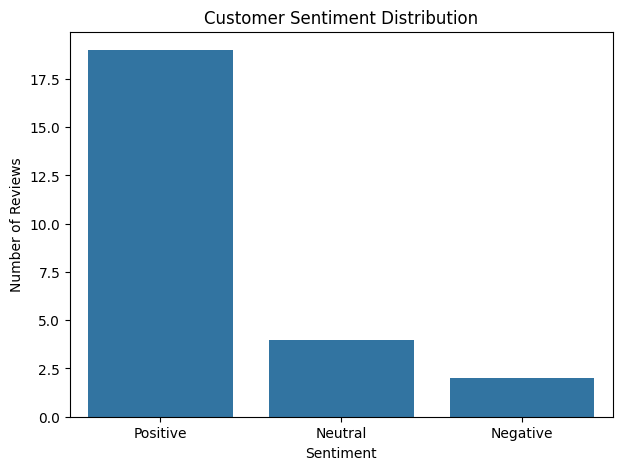

In [ ]:
plt.figure(figsize=(7,5))

sns.countplot(
    data=df,
    x="sentiment"
)

plt.title("Customer Sentiment Distribution")
plt.xlabel("Sentiment")
plt.ylabel("Number of Reviews")

plt.show()

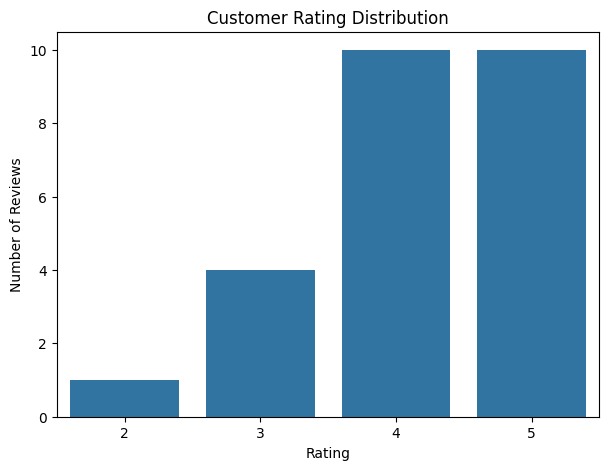

In [ ]:
plt.figure(figsize=(7,5))

sns.countplot(
    data=df,
    x="rating"
)

plt.title("Customer Rating Distribution")
plt.xlabel("Rating")
plt.ylabel("Number of Reviews")

plt.show()

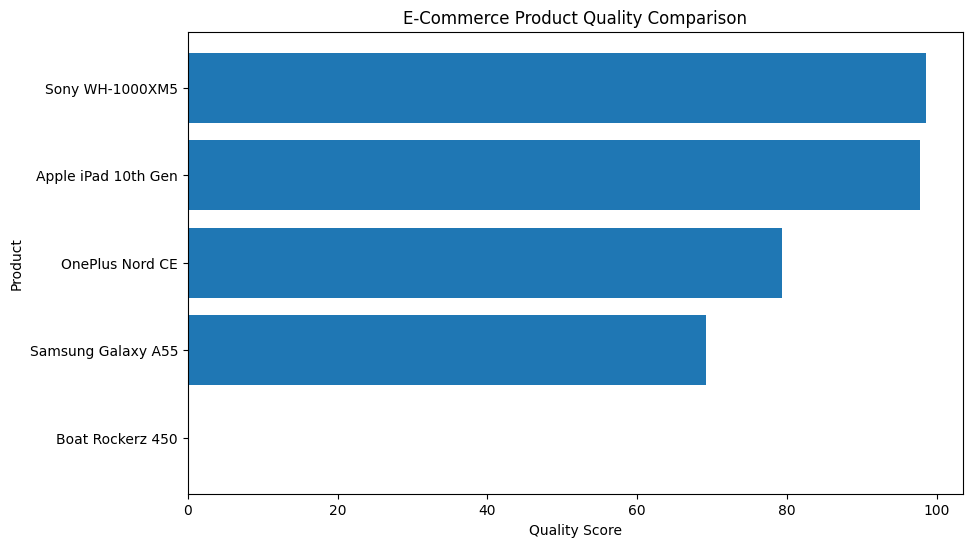

In [ ]:
plt.figure(figsize=(10,6))

plot_df = product_summary.sort_values(
    "final_quality_score",
    ascending=True
)

plt.barh(
    plot_df["product_name"],
    plot_df["final_quality_score"]
)

plt.xlabel("Quality Score")
plt.ylabel("Product")

plt.title(
    "E-Commerce Product Quality Comparison"
)

plt.show()

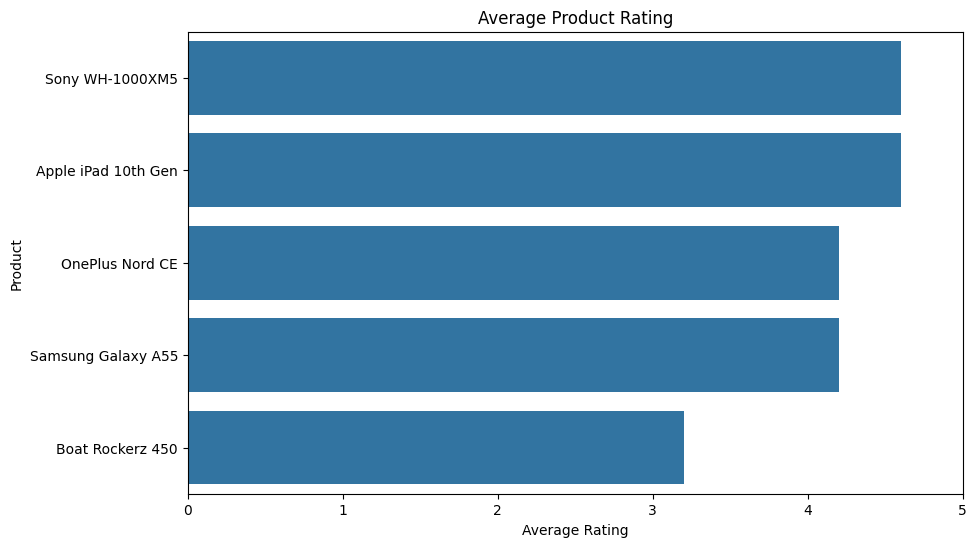

In [ ]:
plt.figure(figsize=(10,6))

sns.barplot(
    data=product_summary,
    x="average_rating",
    y="product_name"
)

plt.title("Average Product Rating")
plt.xlabel("Average Rating")
plt.ylabel("Product")

plt.xlim(0,5)

plt.show()

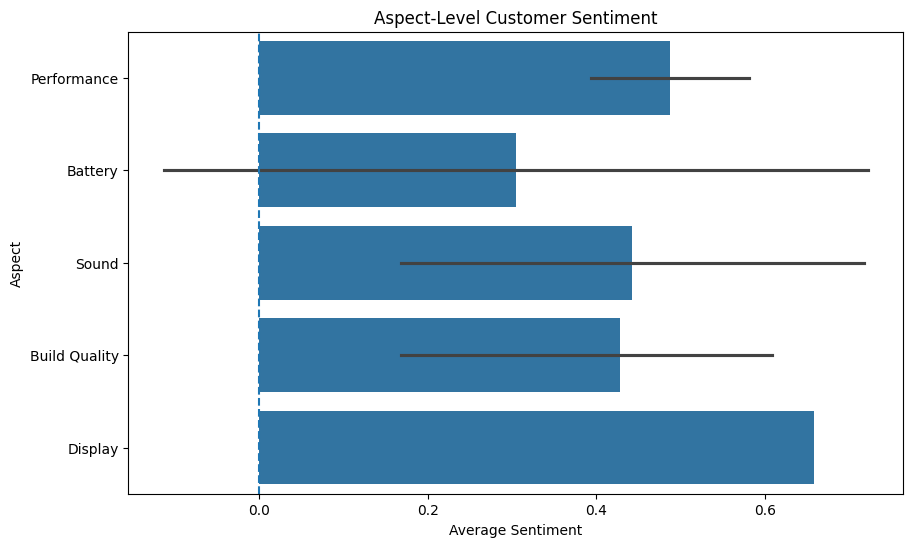

In [ ]:
aspect_plot = aspect_summary.copy()

aspect_plot["sentiment_abs"] = (
    aspect_plot["average_sentiment"].abs()
)

top_aspects = aspect_plot.sort_values(
    "mentions",
    ascending=False
).head(10)

plt.figure(figsize=(10,6))

sns.barplot(
    data=top_aspects,
    x="average_sentiment",
    y="aspect"
)

plt.axvline(
    0,
    linestyle="--"
)

plt.title(
    "Aspect-Level Customer Sentiment"
)

plt.xlabel("Average Sentiment")
plt.ylabel("Aspect")

plt.show()

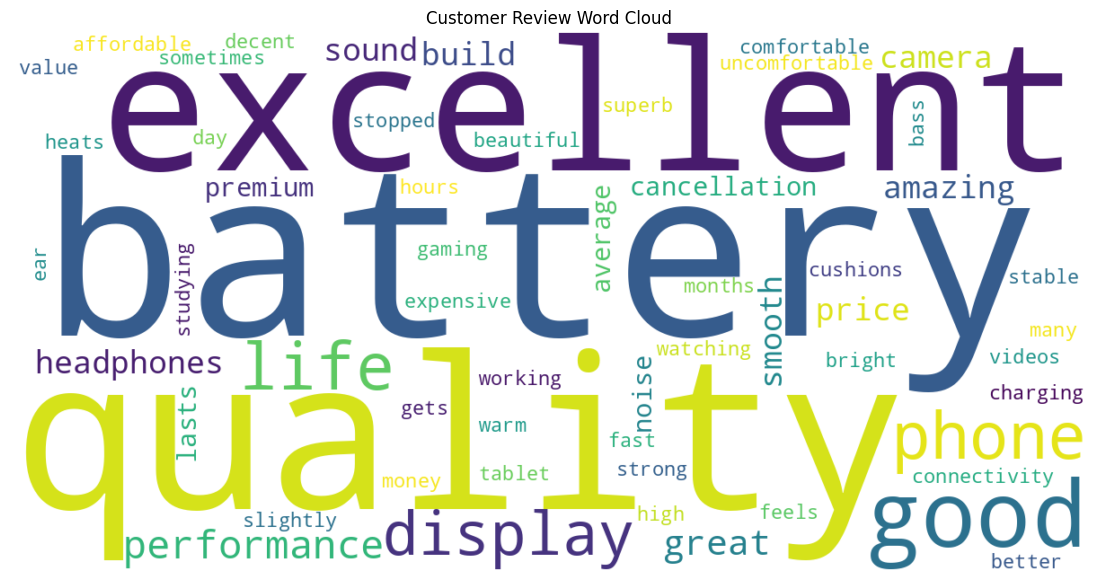

In [ ]:
all_reviews = " ".join(
    df["clean_review"].tolist()
)

wordcloud = WordCloud(
    width=1200,
    height=600,
    background_color="white"
).generate(all_reviews)

plt.figure(figsize=(15,7))

plt.imshow(
    wordcloud,
    interpolation="bilinear"
)

plt.axis("off")

plt.title("Customer Review Word Cloud")

plt.show()

In [ ]:
import plotly.graph_objects as go

print("==============================================")
print("       E-COMMERCE PRODUCT ANALYSIS")
print("==============================================")

print(
    "\nTotal Products:",
    product_summary["product_name"].nunique()
)

print(
    "Total Reviews:",
    len(df)
)

print(
    "Average Rating:",
    round(df["rating"].mean(), 2)
)

print(
    "Positive Reviews:",
    (df["sentiment"] == "Positive").sum()
)

print(
    "Negative Reviews:",
    (df["sentiment"] == "Negative").sum()
)

print(
    "Complaints:",
    df["complaint"].sum()
)

print("\n----------------------------------------------")
print("PRODUCT RANKING")
print("----------------------------------------------")

display(
    product_summary[
        [
            "rank",
            "product_name",
            "average_rating",
            "positive_reviews",
            "negative_reviews",
            "complaints",
            "final_quality_score"
        ]
    ]
)

       E-COMMERCE PRODUCT ANALYSIS

Total Products: 5
Total Reviews: 25
Average Rating: 4.16
Positive Reviews: 19
Negative Reviews: 2
Complaints: 4

----------------------------------------------
PRODUCT RANKING
----------------------------------------------


,rank,product_name,average_rating,positive_reviews,negative_reviews,complaints,final_quality_score
2,1,Sony WH-1000XM5,4.6,4,0,0,98.539079
4,2,Apple iPad 10th Gen,4.6,5,0,1,97.690633
1,3,OnePlus Nord CE,4.2,5,0,0,79.333216
0,4,Samsung Galaxy A55,4.2,3,0,1,69.167381
3,5,Boat Rockerz 450,3.2,2,2,2,0.000000


In [ ]:
fig = px.bar(
    product_summary.sort_values(
        "final_quality_score",
        ascending=True
    ),

    x="final_quality_score",

    y="product_name",

    orientation="h",

    text="final_quality_score",

    title="E-Commerce Product Quality Ranking",

    labels={
        "final_quality_score": "Quality Score",
        "product_name": "Product"
    }
)

fig.update_traces(
    texttemplate="%{text:.1f}",
    textposition="outside"
)

fig.show()

In [ ]:
sentiment_product = df.groupby(
    ["product_name", "sentiment"]
).size().reset_index(
    name="count"
)

fig = px.bar(
    sentiment_product,

    x="product_name",

    y="count",

    color="sentiment",

    barmode="group",

    title="Product-wise Customer Sentiment",

    labels={
        "product_name": "Product",
        "count": "Number of Reviews"
    }
)

fig.show()

In [ ]:
def generate_product_report(product_name):

    product_reviews = df[
        df["product_name"] == product_name
    ]

    product_data = product_summary[
        product_summary["product_name"] == product_name
    ].iloc[0]

    product_aspects = aspect_summary[
        aspect_summary["product_name"] == product_name
    ].sort_values(
        "average_sentiment",
        ascending=False
    )

    print("=" * 60)
    print("PRODUCT RESEARCH REPORT")
    print("=" * 60)

    print("\nProduct:", product_name)

    print(
        f"Overall Quality Score: "
        f"{product_data['final_quality_score']:.2f}/100"
    )

    print(
        f"Average Rating: "
        f"{product_data['average_rating']:.2f}/5"
    )

    print(
        f"Total Reviews: "
        f"{product_data['total_reviews']}"
    )

    print(
        f"Positive Reviews: "
        f"{product_data['positive_reviews']}"
    )

    print(
        f"Negative Reviews: "
        f"{product_data['negative_reviews']}"
    )

    print(
        f"Complaints: "
        f"{product_data['complaints']}"
    )

    print("\nTOP POSITIVE ASPECTS")

    for _, row in product_aspects.head(3).iterrows():

        print(
            f"- {row['aspect']}: "
            f"{row['average_sentiment']:.2f}"
        )

    print("\nTOP NEGATIVE ASPECTS")

    for _, row in product_aspects.tail(3).iterrows():

        print(
            f"- {row['aspect']}: "
            f"{row['average_sentiment']:.2f}"
        )

    print("\nRECOMMENDATION")

    if product_data["final_quality_score"] >= 80:
        print("Highly Recommended")

    elif product_data["final_quality_score"] >= 60:
        print("Recommended")

    elif product_data["final_quality_score"] >= 40:
        print("Consider with Caution")

    else:
        print("Not Recommended")

    print("=" * 60)

In [ ]:
generate_product_report(
    "Sony WH-1000XM5"
)

PRODUCT RESEARCH REPORT

Product: Sony WH-1000XM5
Overall Quality Score: 98.54/100
Average Rating: 4.60/5
Total Reviews: 5
Positive Reviews: 4
Negative Reviews: 0
Complaints: 0

TOP POSITIVE ASPECTS
- Comfort: 0.83
- Battery: 0.73
- Sound: 0.72

TOP NEGATIVE ASPECTS
- Sound: 0.72
- Build Quality: 0.51
- Price: 0.00

RECOMMENDATION
Highly Recommended


In [ ]:
def product_research_agent(query):

    query = query.lower()

    print("USER QUERY:")
    print(query)

    print("\n[Agent 1] Query Analysis")

    # Battery query
    if "battery" in query:

        print("Task identified: Battery aspect analysis")

        battery = aspect_summary[
            aspect_summary["aspect"] == "Battery"
        ]

        if len(battery) > 0:

            result = battery.sort_values(
                "average_sentiment",
                ascending=False
            ).iloc[0]

            print(
                "\nBest product for battery:"
            )

            print(
                result["product_name"]
            )

            print(
                "Battery sentiment:",
                round(
                    result["average_sentiment"],
                    3
                )
            )

            return result

    # Camera query
    elif "camera" in query:

        print("Task identified: Camera aspect analysis")

        camera = aspect_summary[
            aspect_summary["aspect"] == "Camera"
        ]

        if len(camera) > 0:

            result = camera.sort_values(
                "average_sentiment",
                ascending=False
            ).iloc[0]

            print(
                "\nBest product for camera:"
            )

            print(
                result["product_name"]
            )

            return result

    # Price query
    elif "price" in query or "value" in query:

        print("Task identified: Price/value analysis")

        price = aspect_summary[
            aspect_summary["aspect"] == "Price"
        ]

        if len(price) > 0:

            result = price.sort_values(
                "average_sentiment",
                ascending=False
            ).iloc[0]

            print(
                "\nBest product for price/value:"
            )

            print(
                result["product_name"]
            )

            return result

    # Overall query
    else:

        print(
            "Task identified: Overall product ranking"
        )

        result = product_summary.iloc[0]

        print(
            "\nBest overall product:"
        )

        print(
            result["product_name"]
        )

        print(
            "Quality score:",
            round(
                result["final_quality_score"],
                2
            )
        )

        return result

In [ ]:
product_research_agent(
    "Which product has the best battery?"
)

USER QUERY:
which product has the best battery?

[Agent 1] Query Analysis
Task identified: Battery aspect analysis

Best product for battery:
Sony WH-1000XM5
Battery sentiment: 0.726


,21
product_name,Sony WH-1000XM5
aspect,Battery
mentions,2
average_sentiment,0.72585
positive_mentions,2
negative_mentions,0


In [ ]:
product_research_agent(
    "Which product has the best camera?"
)

USER QUERY:
which product has the best camera?

[Agent 1] Query Analysis
Task identified: Camera aspect analysis

Best product for camera:
Samsung Galaxy A55


,17
product_name,Samsung Galaxy A55
aspect,Camera
mentions,2
average_sentiment,0.4466
positive_mentions,1
negative_mentions,0


In [ ]:
product_research_agent(
    "Which product is the best overall?"
)

USER QUERY:
which product is the best overall?

[Agent 1] Query Analysis
Task identified: Overall product ranking

Best overall product:
Sony WH-1000XM5
Quality score: 98.54


,2
product_id,P003
product_name,Sony WH-1000XM5
total_reviews,5
average_rating,4.6
average_sentiment,0.59578
positive_reviews,4
negative_reviews,0
complaints,0
quality_score,0.871156
rating_norm,1.0
